This phase uses a hybrid evaluation framework that combines cultural coding with computational analysis to detect algorithmic bias in how LLMs interpret Yoruba proverbs. It evaluates the cultural and linguistic interpretive capacity of LLMs on Yoruba proverbs across three distinct axes: literal fidelity, cultural alignment, and semantic interpretability. Each method; designed to encapsulate an exclusive dimension of performance, ensuring a comprehensive assessment.

3.2.1 Literal and Interpretation Fidelity: Surface Translation Evaluation. This first method assesses how accurately LLMs can translate Yoruba proverbs into English at the surface level, focusing on semantic fidelity rather than deeper cultural or moral interpretation.This method shows how well these models are able to interpret this language to it’s literal meaning.

A comprehensive dataset has already been created, pairing each Yoruba proverb with their translation and cultural interpretation. Each LLM is tasked with translating the proverbs independently. The LLMs translation quality are evaluated using three automatic metrics:

• BERTScore: Computes sematic similarity using contextualized token embeddings.

• BLEU Score: Measures n-gram overlap between the LLMs translation and the
reference in the dataset.

• Round-trip Translation: compare the back-translated proverb to the original
using BERTScore and BLEU

In [1]:
!pip install bert-score

   ---------------------------------------- 0.0/241.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/241.2 MB 1.5 MB/s eta 0:02:38
   ---------------------------------------- 1.3/241.2 MB 2.8 MB/s eta 0:01:26
   ---------------------------------------- 1.6/241.2 MB 2.2 MB/s eta 0:01:49
   ---------------------------------------- 1.8/241.2 MB 2.1 MB/s eta 0:01:57
   ---------------------------------------- 2.4/241.2 MB 2.0 MB/s eta 0:01:58
   ---------------------------------------- 2.6/241.2 MB 2.0 MB/s eta 0:02:02
   ---------------------------------------- 2.9/241.2 MB 1.9 MB/s eta 0:02:07
    --------------------------------------- 3.1/241.2 MB 1.8 MB/s eta 0:02:12
    --------------------------------------- 3.4/241.2 MB 1.7 MB/s eta 0:02:20
    --------------------------------------- 3.4/241.2 MB 1.7 MB/s eta 0:02:20
    --------------------------------------- 3.7/241.2 MB 1.5 MB/s eta 0:02:36
    --------------------------------------- 3.7/241.2 MB 1.5 MB/s eta 0


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!pip install vaderSentiment


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd

df = pd.read_csv("C:\\Users\\temisola\\Final-Year-Project\\datasets\\yoruba_proverb_final_cleaned.csv")

In [17]:
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\temisola\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [6]:
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

In [3]:
df.head()
df.columns.tolist()

['entry_id',
 'yoruba',
 'english_literal',
 'interpretation_gold',
 'deepseek_translation',
 'claude_translation',
 'gemini_translation',
 'mistral_translation',
 'llama_translation',
 'deepseek_interpretation',
 'claude_interpretation',
 'gemini_interpretation',
 'mistral_interpretation',
 'llama_interpretation']

In [7]:
def sentiment_score(text):
    if pd.isna(text):
        return None
    return sia.polarity_scores(str(text))["compound"]

In [8]:
df["gold_translation_sentiment"] = df["english_literal"].apply(sentiment_score)
df["gold_interpretation_sentiment"] = df["interpretation_gold"].apply(sentiment_score)

In [10]:
translation_models = [
    "deepseek_translation",
    "claude_translation",
    "gemini_translation",
    "mistral_translation",
    "llama_translation"
]

for col in translation_models:
    df[col + "_sentiment"] = df[col].apply(sentiment_score)

In [9]:
interpretation_models = [
    "deepseek_interpretation",
    "claude_interpretation",
    "gemini_interpretation",
    "mistral_interpretation",
    "llama_interpretation"
]

for col in interpretation_models:
    df[col + "_sentiment"] = df[col].apply(sentiment_score)

In [11]:
def sentiment_label(text):
    
    if pd.isna(text):
        return None
        
    score = sia.polarity_scores(str(text))["compound"]
    
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

In [12]:
df["gold_translation_sentiment"] = df["english_literal"].apply(sentiment_label)
df["gold_interpretation_sentiment"] = df["interpretation_gold"].apply(sentiment_label)

In [13]:
translation_models = [
    "deepseek_translation",
    "claude_translation",
    "gemini_translation",
    "mistral_translation",
    "llama_translation"
]

for col in translation_models:
    df[col + "_sentiment"] = df[col].apply(sentiment_label)

In [14]:
interpretation_models = [
    "deepseek_interpretation",
    "claude_interpretation",
    "gemini_interpretation",
    "mistral_interpretation",
    "llama_interpretation"
]

for col in interpretation_models:
    df[col + "_sentiment"] = df[col].apply(sentiment_label)

In [15]:
translation_sentiment_cols = [
    "gold_translation_sentiment",
    "deepseek_translation_sentiment",
    "claude_translation_sentiment",
    "gemini_translation_sentiment",
    "mistral_translation_sentiment",
    "llama_translation_sentiment"
]

translation_counts = pd.DataFrame()

for col in translation_sentiment_cols:
    counts = df[col].value_counts()
    translation_counts[col] = counts

translation_counts = translation_counts.fillna(0)

translation_counts

,gold_translation_sentiment,deepseek_translation_sentiment,claude_translation_sentiment,gemini_translation_sentiment,mistral_translation_sentiment,llama_translation_sentiment
gold_translation_sentiment,,,,,,
neutral,379,416,369,400,403,486
negative,335,291,306,295,315,257
positive,240,247,279,259,236,211


In [16]:
interpretation_sentiment_cols = [
    "gold_interpretation_sentiment",
    "deepseek_interpretation_sentiment",
    "claude_interpretation_sentiment",
    "gemini_interpretation_sentiment",
    "mistral_interpretation_sentiment",
    "llama_interpretation_sentiment"
]

interpretation_counts = pd.DataFrame()

for col in interpretation_sentiment_cols:
    counts = df[col].value_counts()
    interpretation_counts[col] = counts

interpretation_counts = interpretation_counts.fillna(0)

interpretation_counts

,gold_interpretation_sentiment,deepseek_interpretation_sentiment,claude_interpretation_sentiment,gemini_interpretation_sentiment,mistral_interpretation_sentiment,llama_interpretation_sentiment
gold_interpretation_sentiment,,,,,,
positive,336,439,480,432,413,498
neutral,309,130,115,127,94,185
negative,309,385,359,395,447,271


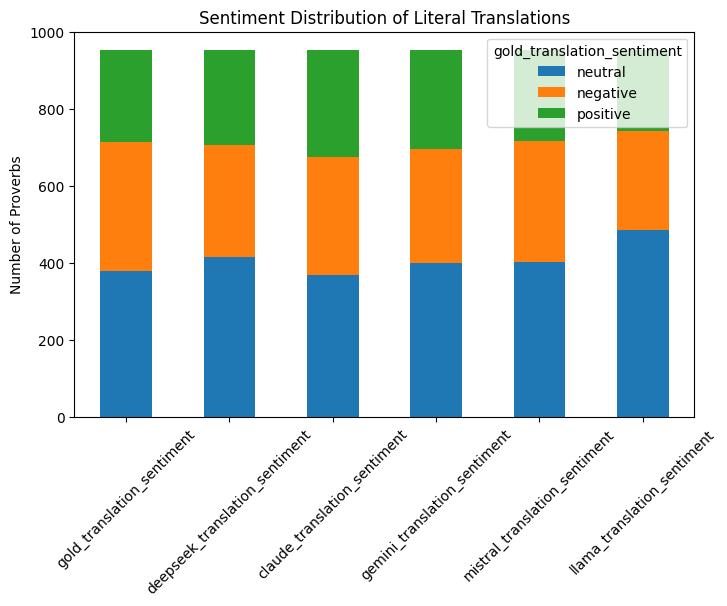

In [18]:
translation_counts.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Sentiment Distribution of Literal Translations")
plt.ylabel("Number of Proverbs")

plt.xticks(rotation=45)

plt.show()

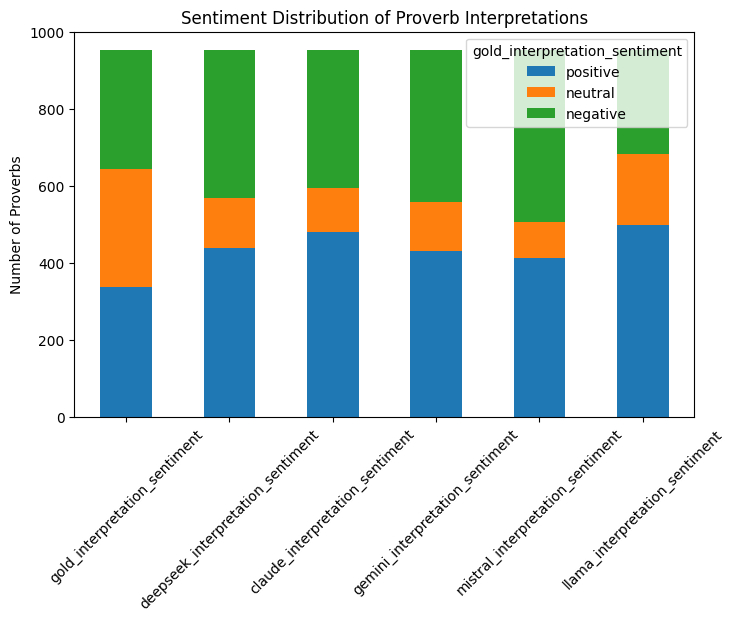

In [19]:
interpretation_counts.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Sentiment Distribution of Proverb Interpretations")
plt.ylabel("Number of Proverbs")

plt.xticks(rotation=45)

plt.show()

In [20]:
sentiment_columns = {
    "Original": "gold_interpretation_sentiment",
    "DeepSeek": "deepseek_interpretation_sentiment",
    "Claude": "claude_interpretation_sentiment",
    "Gemini": "gemini_interpretation_sentiment",
    "Mistral": "mistral_interpretation_sentiment",
    "Llama": "llama_interpretation_sentiment"
}

In [21]:
sentiment_counts = pd.DataFrame()

for model, col in sentiment_columns.items():
    counts = df[col].value_counts()
    sentiment_counts[model] = counts

sentiment_counts = sentiment_counts.fillna(0)

sentiment_counts

,Original,DeepSeek,Claude,Gemini,Mistral,Llama
gold_interpretation_sentiment,,,,,,
positive,336,439,480,432,413,498
neutral,309,130,115,127,94,185
negative,309,385,359,395,447,271


In [22]:
sentiment_table = df[[
    "entry_id",
    "yoruba",
    
    "english_literal",
    "interpretation_gold",
    
    "gold_translation_sentiment",
    "gold_interpretation_sentiment",
    
    "deepseek_translation",
    "deepseek_interpretation",
    "deepseek_interpretation_sentiment",
    
    "claude_translation",
    "claude_interpretation",
    "claude_interpretation_sentiment",
    
    "gemini_translation",
    "gemini_interpretation",
    "gemini_interpretation_sentiment",
    
    "mistral_translation",
    "mistral_interpretation",
    "mistral_interpretation_sentiment",
    
    "llama_translation",
    "llama_interpretation",
    "llama_interpretation_sentiment"
]].copy()

sentiment_table.head()

,entry_id,yoruba,english_literal,interpretation_gold,gold_translation_sentiment,gold_interpretation_sentiment,deepseek_translation,deepseek_interpretation,deepseek_interpretation_sentiment,claude_translation,...,claude_interpretation_sentiment,gemini_translation,gemini_interpretation,gemini_interpretation_sentiment,mistral_translation,mistral_interpretation,mistral_interpretation_sentiment,llama_translation,llama_interpretation,llama_interpretation_sentiment
0,016beb1f83885794,Àgbéré àwòdì ní ńní òun ó jẹ ìgbín.,It is an overreaching kite that proposes to ea...,Know your limits.,neutral,neutral,The kite's talon says it will eat the snail.,This proverb warns against making empty boasts...,negative,The kite that carries snails says it will eat ...,...,positive,The hawk's foolishness is that it thinks it wi...,It is foolish to attempt something impossible ...,negative,The kite boasts that it will eat the snail.,It warns against overconfidence in one's abili...,negative,The snail shell is what the snail eats.,One's circumstances or resources can be the so...,neutral
1,041e7cc871bfebac,A kì í kórira ọ̀fọ́n-ọ̀n ká finá bọ ahéré.,One does not so hate the bush rat that one set...,One should not destroy oneself simply to get a...,positive,negative,We do not hate the grinding stone and use fire...,Do not destroy something useful while expressi...,negative,One does not hate a wasp so much as to use fir...,...,neutral,One does not hate the buffalo so much as to se...,One should not cause greater harm to oneself o...,neutral,We do not gather dry twigs to set a hut on fire,One should not deliberately create or escalate...,negative,We do not use a single rope to tie a bundle of...,Unity and cooperation are necessary to achieve...,neutral
2,04d43584d1d8404a,A kì í bọ òrìṣà lójú ọ̀fọ́n-ọ̀n; bó bá dalé...,One does not sacrifice to a god in the presenc...,Do not do things that might constitute temptat...,negative,neutral,We do not worship the deity in the presence of...,This proverb advises discretion and the import...,positive,One does not worship a deity in the presence o...,...,positive,One does not worship an Orisha in the open; wh...,It is unwise to perform sacred rituals or reve...,negative,We do not worship the deity in the presence of...,"Laziness hinders progress, but persistence and...",positive,We do not worship the god of the forest in the...,One should respect the norms and conventions o...,positive
3,0524e60d4f486d54,"Àrí-ì-gbọdọ̀-wí, baálé ilé yọkun lémú.","Something-seen-but-unmentionable, the man of t...","When a venerable person acts like a fool, few ...",neutral,negative,"The one who says 'I must not speak', the landl...",Silence in the face of wrongdoing can lead to ...,negative,"The one who must not be spoken against, the he...",...,positive,"The one who sees but must not speak, the head ...",This proverb describes a situation where one i...,negative,"The one who must not be scolded, the head of t...",A person who is above reproach often has hidde...,negative,"The one who does not listen to advice, the own...",Disregarding advice can lead to loss and chaos.,negative
4,0584b5795ae7ccb8,Àwòrò tí a ò bá lù kì í luni.,A priest one does not hit does not hit one.,A person who wants to be respected must respec...,neutral,positive,The hoe that is not used does not have an owner.,Unused resources or tools are neglected and lo...,negative,The plate that is not beaten does not make sound.,...,neutral,A priest that we do not beat does not beat us.,One should not provoke or antagonize others if...,positive,A drummer that one does not pay does not play ...,People expect compensation or appreciation for...,positive,The dawn that we did not greet will not greet us.,One must acknowledge and respect the beginning...,positive


In [23]:
models = ["deepseek", "claude", "gemini", "mistral", "llama"]

for m in models:
    df[f"{m}_sentiment_discrepancy"] = (
        df[f"{m}_interpretation_sentiment"]
        != df["gold_interpretation_sentiment"]
    )

In [24]:
discrepancy_counts = {}

for m in models:
    discrepancy_counts[m] = df[f"{m}_sentiment_discrepancy"].sum()

discrepancy_df = pd.DataFrame(
    discrepancy_counts.items(),
    columns=["Model", "Sentiment_Discrepancies"]
)

discrepancy_df

,Model,Sentiment_Discrepancies
0,deepseek,584
1,claude,596
2,gemini,581
3,mistral,600
4,llama,617


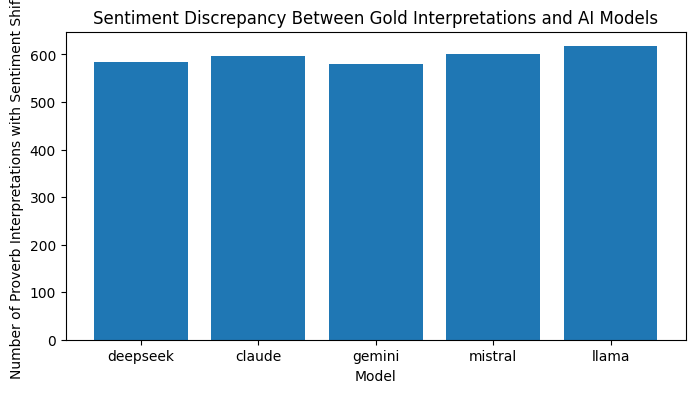

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.bar(
    discrepancy_df["Model"],
    discrepancy_df["Sentiment_Discrepancies"]
)

plt.title("Sentiment Discrepancy Between Gold Interpretations and AI Models")
plt.ylabel("Number of Proverb Interpretations with Sentiment Shift")
plt.xlabel("Model")

plt.show()

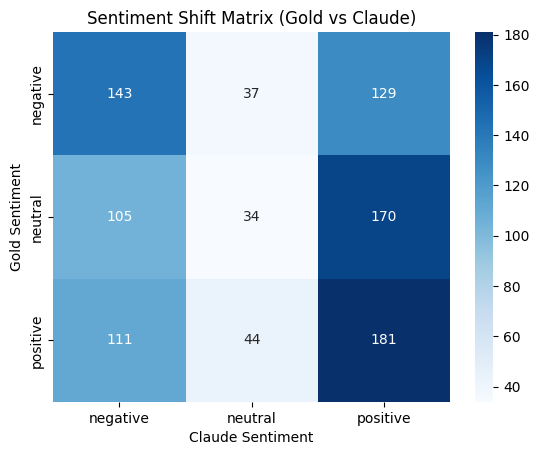

In [34]:
import seaborn as sns

conf_matrix = pd.crosstab(
    df["gold_interpretation_sentiment"],
    df["claude_interpretation_sentiment"]
)

sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")

plt.title("Sentiment Shift Matrix (Gold vs Claude)")
plt.xlabel("Claude Sentiment")
plt.ylabel("Gold Sentiment")

plt.show()

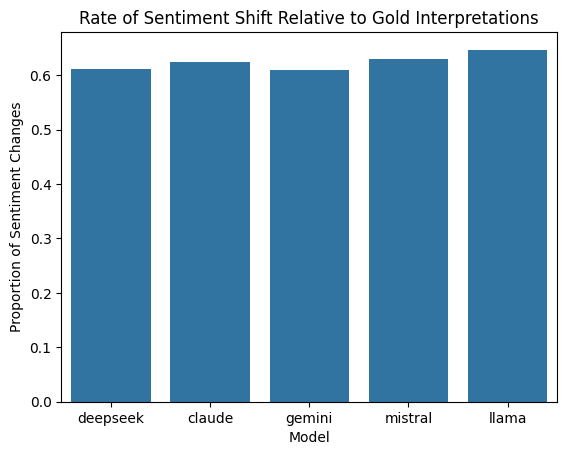

In [32]:
shift_rates = []

for m in models:
    shift_rate = (
        df[f"{m}_interpretation_sentiment"]
        != df["gold_interpretation_sentiment"]
    ).mean()
    
    shift_rates.append({
        "Model": m,
        "Shift_Rate": shift_rate
    })

shift_df = pd.DataFrame(shift_rates)

sns.barplot(
    data=shift_df,
    x="Model",
    y="Shift_Rate"
)

plt.title("Rate of Sentiment Shift Relative to Gold Interpretations")
plt.ylabel("Proportion of Sentiment Changes")

plt.show()

on to BLEU for literal translation fidelity

In [38]:
!pip install bleu


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
!pip install sacrebleu


   ---------------------------------------- 0/3 [tabulate]
   ---------------------------------------- 0/3 [tabulate]
   ------------- -------------------------- 1/3 [portalocker]
   ------------- -------------------------- 1/3 [portalocker]
   ------------- -------------------------- 1/3 [portalocker]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- ------------- 2/3 [sacrebleu]
   -------------------------- -----


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
ref_translation_col = "english_literal"

model_translation_cols = [
    "deepseek_translation",
    "claude_translation",
    "gemini_translation",
    "mistral_translation",
    "llama_translation"
]

print(df[[ref_translation_col] + model_translation_cols].head())

                                     english_literal  \
0  It is an overreaching kite that proposes to ea...   
1  One does not so hate the bush rat that one set...   
2  One does not sacrifice to a god in the presenc...   
3  Something-seen-but-unmentionable, the man of t...   
4        A priest one does not hit does not hit one.   

                                deepseek_translation  \
0       The kite's talon says it will eat the snail.   
1  We do not hate the grinding stone and use fire...   
2  We do not worship the deity in the presence of...   
3  The one who says 'I must not speak', the landl...   
4   The hoe that is not used does not have an owner.   

                                  claude_translation  \
0  The kite that carries snails says it will eat ...   
1  One does not hate a wasp so much as to use fir...   
2  One does not worship a deity in the presence o...   
3  The one who must not be spoken against, the he...   
4  The plate that is not beaten does not make 

In [41]:
import sacrebleu

bleu_results = []

references = df[ref_translation_col].astype(str).tolist()

for col in model_translation_cols:
    hypotheses = df[col].astype(str).tolist()
    bleu = sacrebleu.corpus_bleu(hypotheses, [references])

    bleu_results.append({
        "model": col,
        "bleu_score": bleu.score
    })

bleu_df = pd.DataFrame(bleu_results).sort_values("bleu_score", ascending=False)
print(bleu_df)

                  model  bleu_score
2    gemini_translation   17.123140
1    claude_translation   13.449049
3   mistral_translation   10.545134
0  deepseek_translation   10.525482
4     llama_translation    5.300244


In [43]:
from bert_score import score

bertscore_results = []

references = df[ref_translation_col].astype(str).tolist()

for col in model_translation_cols:
    candidates = df[col].astype(str).tolist()

    P, R, F1 = score(candidates, references, lang="en", verbose=True)

    bertscore_results.append({
        "model": col,
        "bert_precision_mean": float(P.mean()),
        "bert_recall_mean": float(R.mean()),
        "bert_f1_mean": float(F1.mean())
    })

bertscore_df = pd.DataFrame(bertscore_results).sort_values(
    "bert_f1_mean", ascending=False
)

print(bertscore_df)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


calculating scores...
computing bert embedding.


  0%|          | 0/30 [00:00<?, ?it/s]

...

calculating scores...
computing bert embedding.


  0%|          | 0/30 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/15 [00:00<?, ?it/s]

done in 493.23 seconds, 1.93 sentences/sec
                  model  bert_precision_mean  bert_recall_mean  bert_f1_mean
2    gemini_translation             0.915873          0.907952      0.911803
1    claude_translation             0.903024          0.897563      0.900213
0  deepseek_translation             0.899917          0.889288      0.894496
3   mistral_translation             0.892810          0.889343      0.890998
4     llama_translation             0.879317          0.872352      0.875755


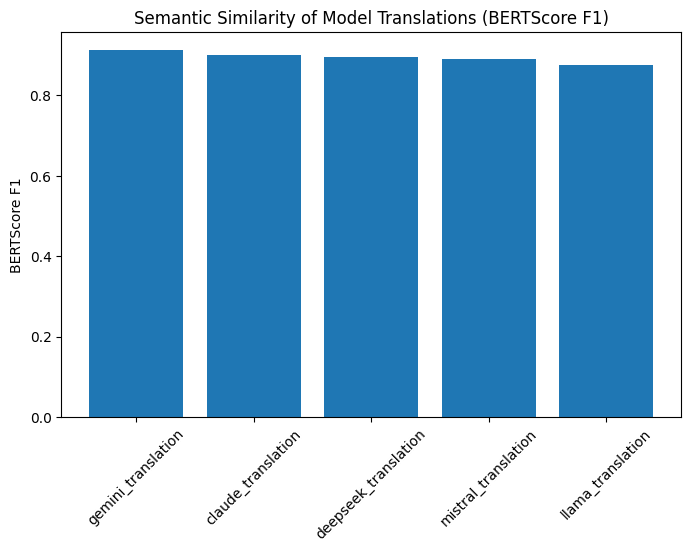

In [44]:
plt.figure(figsize=(8,5))

plt.bar(
    bertscore_df["model"],
    bertscore_df["bert_f1_mean"]
)

plt.title("Semantic Similarity of Model Translations (BERTScore F1)")
plt.ylabel("BERTScore F1")

plt.xticks(rotation=45)

plt.show()